In [2]:
import pickle
import json
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt

import requests
from PIL import Image

In [5]:
import os
import sys
from pathlib import Path

cwd = Path.cwd().resolve()
root_override = os.environ.get("OCL_PROJECT_ROOT")
candidates = [Path(root_override).resolve()] if root_override else [cwd, *cwd.parents]
project_root = next((p for p in candidates if (p / "src/dataset.py").is_file()), None)
if project_root is None:
    raise RuntimeError("Open the notebook from the OCL workspace or set OCL_PROJECT_ROOT.")

sys.path.insert(0, str(project_root))
data_root = Path(os.environ.get("OCL_DATA_ROOT", project_root / "data"))
resource_root = Path(os.environ.get("OCL_RESOURCE_ROOT", data_root / "resources"))



with open(resource_root / "OCL_annot_test.pkl", "rb") as f:
    test_data = pickle.load(f)

def load_json(filename):
    with open(resource_root / filename, "r", encoding="utf-8") as f:
        return json.load(f)

categories = load_json("OCL_class_object.json")
attributes = load_json("OCL_class_attribute.json")
affordances = load_json("OCL_class_affordance.json")

print("Resource path:", resource_root)
print("Number of images:", len(test_data))
print("Number of categories:", len(categories))
print("Number of attributes:", len(attributes))
print("Number of affordances:", len(affordances))

Resource path: c:\Users\lishi\Desktop\ai\OCL\data\resources
Number of images: 9101
Number of categories: 381
Number of attributes: 114
Number of affordances: 170


In [4]:
image = test_data[0]
obj = image["objects"][0]

print("Image path:", image["name"])
print("Source:", image["source"])
print("Category:", obj["obj"])
print("Bounding box:", obj["box"])

print("\nAttributes:")
print([attributes[i] for i in obj["attr"]])

print("\nAffordances:")
print([affordances[i]["word"][0] for i in obj["aff"]])

Image path: ImageNet/train/n02917067/n02917067_10348.JPEG
Source: ImageNet
Category: train
Bounding box: [54, 84, 209, 216]

Attributes:
['cool', 'large', 'small', 'old', 'hard', 'heavy', 'blue', 'dry', 'whole', 'long', 'solid', 'smooth', 'horizontal', 'metal', 'wide', 'parked', 'reflective']

Affordances:
['assemble', 'board', 'break', 'brush', 'check', 'clean', 'climb', 'close', 'drive', 'edit', 'exit', 'function', 'hit', 'hit', 'hop on', 'inspect', 'install', 'jump', 'kick', 'kick', 'lie', 'lie', 'lie down', 'load', 'move', 'occupy', 'open', 'open', 'operate', 'paint', 'photograph', 'produce', 'reach', 'repair', 'shoot', 'sign', 'sit', 'sit', 'stand', 'stand', 'stand', 'steer', 'sweep', 'touch', 'transport', 'work', 'write', 'flush', 'park', 'launch', 'watch', 'watch', 'tag']


In [5]:
category_counts = Counter()

for image in test_data:
    for obj in image["objects"]:
        category = obj["obj"]
        category_counts[category] += 1

top10 = category_counts.most_common(10)

print("Total objects:", sum(category_counts.values()))
print("Unique categories:", len(category_counts))

for category, count in top10:
    print(category, count)

Total objects: 25617
Unique categories: 221
car 1599
broccoli 1282
boat 1271
horse 1229
dog 1056
banana 1050
truck 1042
motorcycle 1011
zebra 928
sheep 920


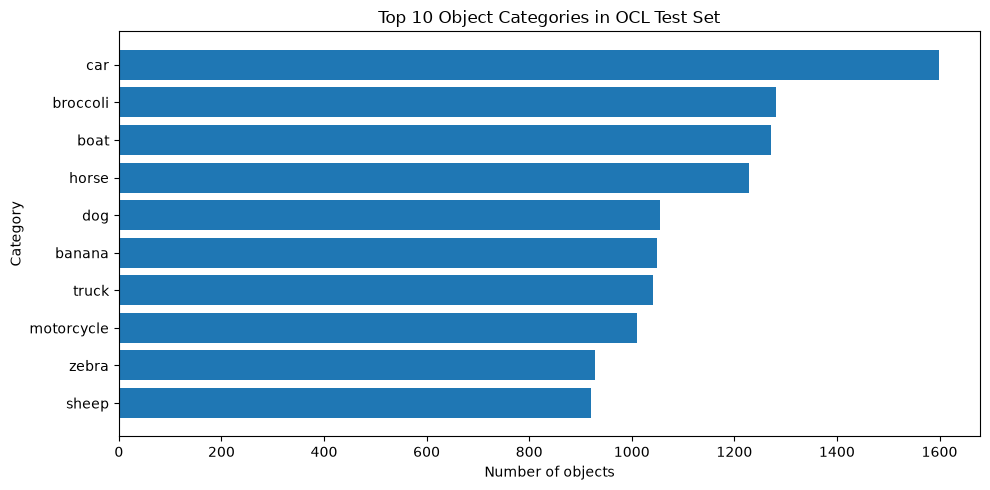

In [6]:
names = [item[0] for item in top10]
counts = [item[1] for item in top10]

plt.figure(figsize=(10, 5))
plt.barh(names, counts)

plt.gca().invert_yaxis()

plt.xlabel("Number of objects")
plt.ylabel("Category")
plt.title("Top 10 Object Categories in OCL Test Set")

plt.tight_layout()
plt.show()

In [9]:
top10_categories = {item[0] for item in top10}

samples = []

for image in test_data:
    for obj in image["objects"]:

        if obj["obj"] in top10_categories:
            sample = {
                "name": image["name"],
                "source": image["source"],
                "category": obj["obj"],
                "box": obj.get("box"),
                "attr": obj["attr"],
                "aff": obj["aff"]
            }

            samples.append(sample)

print("Number of selected objects:", len(samples))
print(samples[0])

Number of selected objects: 11388
{'name': 'ImageNet/train/n03447447/n03447447_1897.JPEG', 'source': 'ImageNet', 'category': 'boat', 'box': [119, 120, 162, 225], 'attr': [6, 11, 12, 15, 16, 19, 22, 25, 29, 35, 38, 45, 47, 48, 52, 53, 58, 64, 65, 76, 92], 'aff': [1, 6, 7, 8, 15, 16, 17, 24, 25, 27, 30, 32, 35, 37, 38, 42, 45, 46, 48, 50, 52, 53, 54, 55, 56, 58, 64, 65, 67, 70, 71, 72, 73, 74, 76, 80, 84, 86, 87, 88, 93, 94, 95, 96, 97, 102, 104, 105, 110, 115, 123, 128, 132, 158, 160, 164, 165, 168]}


In [10]:
source_object_counts = Counter()
source_images = {}

for sample in samples:
    source = sample["source"]
    name = sample["name"]
    source_object_counts[source] += 1
    
    if source not in source_images:
        source_images[source] = set()

    source_images[source].add(name)


for source in source_object_counts:
    print(
        source,
        "Objects:", source_object_counts[source],
        "Images:", len(source_images[source])
    )

ImageNet Objects: 361 Images: 309
COCO Objects: 10108 Images: 3359
from_web Objects: 919 Images: 483


In [ ]:
assert len(samples) == sum(count for _, count in top10)

assert all(
    sample["category"] in top10_categories
    for sample in samples
)

assert all(
    0 <= i < len(attributes)
    for sample in samples
    for i in sample["attr"]
)

assert all(
    0 <= i < len(affordances)
    for sample in samples
    for i in sample["aff"]
)


All checks passed.


from the top,we know we only need to get COCO/ImageNet/from_web

In [14]:
manifest = {source: sorted(names) for source, names in source_images.items()}
manifest_path = data_root / "image_manifest.json"
if manifest_path.is_file():
    saved = json.loads(manifest_path.read_text(encoding="utf-8-sig"))
    if saved != manifest:
        raise ValueError("The existing manifest differs. Use a separate data root to generate a new one.")
    print("Existing manifest verified:", manifest_path)
else:
    data_root.mkdir(parents=True, exist_ok=True)
    with manifest_path.open("x", encoding="utf-8") as stream:
        json.dump(manifest, stream, indent=2)
    print("Manifest saved:", manifest_path)

Manifest saved.


In [15]:
for source, names in manifest.items():
    print(f"\n{source}:")

    for name in names[:5]:
        print(name)


ImageNet:
ImageNet/train/n02085620/n02085620_13855.JPEG
ImageNet/train/n02085620/n02085620_5624.JPEG
ImageNet/train/n02085620/n02085620_9641.JPEG
ImageNet/train/n02085620/n02085620_9779.JPEG
ImageNet/train/n02085782/n02085782_1460.JPEG

COCO:
COCO/train2014/COCO_train2014_000000000821.jpg
COCO/train2014/COCO_train2014_000000000984.jpg
COCO/train2014/COCO_train2014_000000001315.jpg
COCO/train2014/COCO_train2014_000000001319.jpg
COCO/train2014/COCO_train2014_000000001323.jpg

from_web:
from_web/test_0001.jpg
from_web/test_0002.jpg
from_web/test_0003.jpg
from_web/test_0004.jpg
from_web/test_0005.jpg


In [16]:
coco_folders = Counter(
    str(Path(name).parent)
    for name in manifest["COCO"]
)

print(coco_folders)

Counter({'COCO\\val2014': 2051, 'COCO\\train2014': 1308})


In [17]:
url_mapping = load_json("url_to_filename.json")

print(type(url_mapping))
print(len(url_mapping))
print(url_mapping[:3])

<class 'list'>
3422
[['http://5b0988e595225.cdn.sohucs.com/images/20170814/914ce06bad164ec79008d8ac623c7927.jpeg', 'from_web/train_0001.jpeg'], ['http://img2.cn.china.cn/2/2_73_17812_500_302.jpg', 'from_web/train_0003.jpg'], ['http://vipimg.dns4.cn/pic/106812/tongmads/20161115152057_5515_zs_sy.jpg', 'from_web/train_0004.jpg']]


In [26]:
from io import BytesIO

name = manifest["COCO"][0]
image_path = data_root / name
if image_path.is_file():
    image_bytes = image_path.read_bytes()
    print("Using the local image:", image_path)
else:
    split, filename = image_path.parent.name, image_path.name
    url = f"https://images.cocodataset.org/{split}/{filename}"
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    image_bytes = response.content
    print("Loaded for display only:", url)

200
image/jpeg
c:\Users\lishi\Desktop\ai\OCL\data\COCO\train2014\COCO_train2014_000000000821.jpg


(512, 640)
L


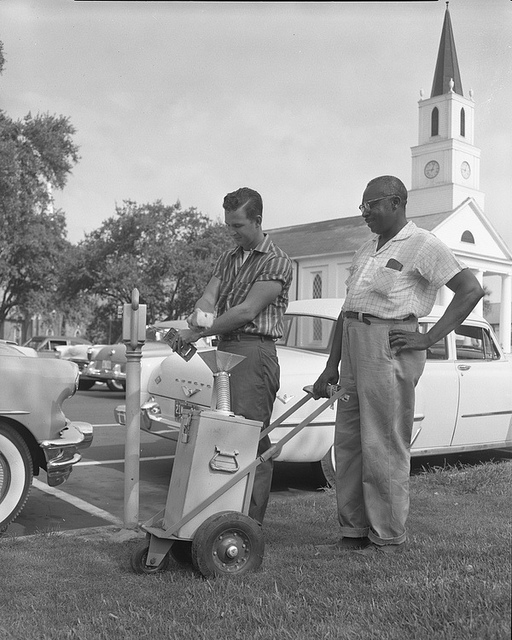

In [27]:
image = Image.open(BytesIO(image_bytes))

print(image.size)
print(image.mode)

display(image)

In [28]:
web_url_dict = {
    filename: url
    for url, filename in url_mapping
}

In [29]:
web_available = []
web_missing = []

for name in manifest["from_web"]:
    if name in web_url_dict:
        web_available.append(name)
    else:
        web_missing.append(name)

print("Total:", len(manifest["from_web"]))
print("URL available:", len(web_available))
print("URL missing:", len(web_missing))

print(web_missing[:5])

Total: 483
URL available: 360
URL missing: 123
['from_web/test_0001.jpg', 'from_web/test_0003.jpg', 'from_web/test_0005.jpg', 'from_web/test_0007.jpg', 'from_web/test_0009.jpg']
